# Held-out IDSSE benchmark

This notebook validates the possession models on **unseen IDSSE matches**, not on the public BAR-ATH ground truth that was used for model selection.

It runs two panels:

- **Panel A, fair IDSSE-only comparison:** nearest-player baseline, physical HMM, Bundesliga-trained HMM, HMM ensemble.
- **Panel B, BAR-ATH transfer:** TCN and consensus. IDSSE has no Smart Tagging, so the set-piece features are neutralised.

> `J03WMX` is used to train `models/bundesliga_weights.json`. Never use it as a held-out match. The default matches are `J03WN1` and `J03WPY`, both unseen.

Runtime: use a CPU runtime. The two position files are about 390 MB each, and the full run usually takes a few minutes.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "evaluation" / "possession_metrics.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "evaluation" / "possession_metrics.py").exists():
    matches = list(Path("/content").glob("*/evaluation/possession_metrics.py"))
    if matches:
        ROOT = matches[0].parents[1]
if not (ROOT / "evaluation" / "possession_metrics.py").exists():
    raise RuntimeError("Open this notebook from a clone of the repository, or clone it into /content first.")
sys.path.insert(0, str(ROOT / "models"))
print(ROOT)

C:\Barcelona2026\more-than-a-hack-2027


## Configuration

Keep `download=True` on Colab. The module downloads the two XML files per match into `/content/idsse` and writes results into `/content/heldout_out`.

If you want a faster smoke run, set `MATCHES = ["J03WN1"]` and `BOOTSTRAP = 250` first, then rerun with both matches and 1000 draws.

In [2]:
from heldout_idesse import run_benchmark

MATCHES = ["J03WN1", "J03WPY"]
DATA_DIR = Path("/content/idsse")
OUT_DIR = Path("/content/heldout_out")
BOOTSTRAP = 1000

summary = run_benchmark(
    matches=MATCHES,
    data_dir=DATA_DIR,
    out_dir=OUT_DIR,
    bootstrap=BOOTSTRAP,
    download=True,
)


=== J03WN1 ===
downloading https://huggingface.co/datasets/pysport/idsse-data/resolve/main/DFL_02_01_matchinformation_DFL-COM-000001_DFL-MAT-J03WN1.xml
downloading https://huggingface.co/datasets/pysport/idsse-data/resolve/main/DFL_04_03_positions_raw_observed_DFL-COM-000001_DFL-MAT-J03WN1.xml
  329 MB
Computing hierarchical emission distributions...
Computing emissions using Bundesliga-trained weights...
Computing hierarchical emission distributions...
Computing emissions using Bundesliga-trained weights...

=== J03WPY ===
downloading https://huggingface.co/datasets/pysport/idsse-data/resolve/main/DFL_02_01_matchinformation_DFL-COM-000002_DFL-MAT-J03WPY.xml
downloading https://huggingface.co/datasets/pysport/idsse-data/resolve/main/DFL_04_03_positions_raw_observed_DFL-COM-000002_DFL-MAT-J03WPY.xml
  298 MB
Computing hierarchical emission distributions...
Computing emissions using Bundesliga-trained weights...
Computing hierarchical emission distributions...
Computing emissions using 

## Per-match results

`spell_f1` is the ranking metric. `spell_lo` and `spell_hi` are the 5-95% bootstrap interval over ground-truth possessions. `macro_f1` is the frame-level tie-break.

In [3]:
summary["per_match"]

,match,panel,model,spell_f1,spell_lo,spell_hi,macro_f1,alive_dead_f1,n_gt_spells,n_pred_spells,n_graded,transitions_25
0,J03WN1,A,baseline_nearest,0.139501,0.129847,0.149638,0.660156,0.821201,500,1986,141561,0.361121
1,J03WN1,A,hmm_physical,0.372881,0.335085,0.407264,0.731225,0.852449,500,326,141561,0.369942
2,J03WN1,A,hmm_bundesliga,0.365133,0.328789,0.400000,0.699961,0.826292,500,326,141561,0.366502
3,J03WN1,A,hmm_ensemble,0.354634,0.317073,0.389293,0.737605,0.854175,500,320,141561,0.361004
4,J03WN1,B,tcn_clean,0.325220,0.289561,0.359348,0.675620,0.830003,500,297,141561,0.328907
5,J03WN1,B,consensus,0.303759,0.268647,0.336341,0.707903,0.850077,500,298,141561,0.302970
6,J03WPY,A,baseline_nearest,0.109366,0.100430,0.118940,0.679731,0.853077,421,2088,146211,0.299925
7,J03WPY,A,hmm_physical,0.396067,0.358427,0.436545,0.776446,0.894671,421,291,146211,0.351770
8,J03WPY,A,hmm_bundesliga,0.391185,0.352590,0.430303,0.739411,0.872531,421,305,146211,0.360221
9,J03WPY,A,hmm_ensemble,0.375000,0.338861,0.413361,0.770157,0.889054,421,299,146211,0.338395


## Pooled results

The pooled row concatenates the matches with an X separator, so no possession or transition is scored across matches.

In [4]:
summary["pooled"]

,match,panel,model,spell_f1,spell_lo,spell_hi,macro_f1,alive_dead_f1,n_gt_spells,n_pred_spells,n_graded,transitions_25
0,POOLED,A,baseline_nearest,0.124364,0.117874,0.130851,0.672656,0.838251,921,4074,287772,0.330529
1,POOLED,A,hmm_physical,0.383615,0.357087,0.411704,0.756706,0.875039,921,617,287772,0.361483
2,POOLED,A,hmm_bundesliga,0.377320,0.350503,0.404124,0.722436,0.850964,921,631,287772,0.363542
3,POOLED,A,hmm_ensemble,0.364156,0.338688,0.389364,0.757172,0.872992,921,619,287772,0.350358
4,POOLED,B,tcn_clean,0.341549,0.315677,0.368498,0.696573,0.850725,921,564,287772,0.342919
5,POOLED,B,consensus,0.325234,0.299853,0.350080,0.730172,0.869358,921,577,287772,0.309623


## Paired differences

Positive `difference` means model A beats model B. `fraction_a_better` is the fraction of paired bootstrap draws where A wins. The key row is `consensus` minus `tcn_clean`.

In [5]:
summary["paired"]

,match,model_a,model_b,difference,low,high,fraction_a_better
0,J03WN1,consensus,tcn_clean,-0.021460,-0.038554,-0.004863,0.020
1,J03WN1,consensus,hmm_ensemble,-0.050875,-0.078763,-0.025150,0.002
2,J03WN1,tcn_clean,hmm_ensemble,-0.029415,-0.059577,-0.002311,0.039
3,J03WN1,hmm_bundesliga,hmm_physical,-0.007748,-0.027119,0.012107,0.262
4,J03WPY,consensus,tcn_clean,-0.010751,-0.027513,0.004852,0.128
5,J03WPY,consensus,hmm_ensemble,-0.025286,-0.050432,-0.000206,0.050
6,J03WPY,tcn_clean,hmm_ensemble,-0.014535,-0.041895,0.014589,0.210
7,J03WPY,hmm_bundesliga,hmm_physical,-0.004883,-0.021650,0.011698,0.270
8,POOLED,consensus,tcn_clean,-0.016315,-0.028197,-0.004414,0.010
9,POOLED,consensus,hmm_ensemble,-0.038922,-0.056917,-0.020425,0.001


## Plot

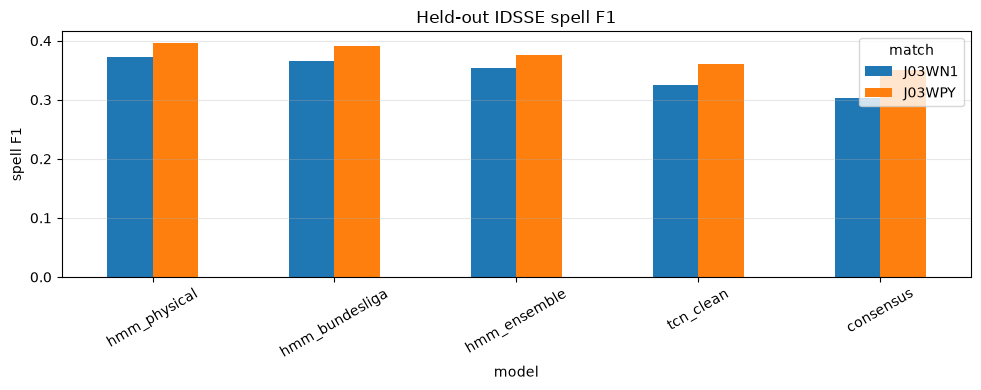

In [6]:
import matplotlib.pyplot as plt

order = ["hmm_physical", "hmm_bundesliga", "hmm_ensemble", "tcn_clean", "consensus"]
frame = summary["per_match"]
pivot = frame.pivot(index="model", columns="match", values="spell_f1").reindex(order)
ax = pivot.plot.bar(figsize=(10, 4), rot=30)
ax.set_ylabel("spell F1")
ax.set_title("Held-out IDSSE spell F1")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## How to read this

- Panel A is the clean comparison: all models see the same IDSSE-only information.
- Panel B is a transfer test. The TCN and consensus were trained/tuned on BAR-ATH and receive neutralised set-piece features here, so a drop is expected. A win is still meaningful; a loss is not proof that they are worse on the private BAR-ATH match.
- If `consensus` beats `tcn_clean` on both unseen matches and in the pooled row, the case for switching the final submission is stronger. If it loses, keep the current `model_tcn_clean` submission.
- Do not compare these absolute scores with the public BAR-ATH scoreboard: the matches, camera data and label coverage differ.

The full JSON, CSV and markdown report are in `OUT_DIR`.